# 1. Construção da base e análise exploratória

**Pergunta de negócio:** quais pedidos têm maior risco de receber uma avaliação negativa (nota 1 ou 2), para que o time de atendimento possa agir antes de o cliente avaliar?

Avaliações ruins afetam a reputação dos vendedores e da plataforma, e reduzem a conversão de vendas futuras. Se conseguirmos identificar os pedidos de risco com antecedência, dá para entrar em contato, explicar um atraso, oferecer uma compensação ou resolver o problema antes que ele vire uma nota 1.

Este notebook cobre:

1. Os dados disponíveis
2. **O momento exato em que a previsão acontece** (a decisão mais importante do projeto)
3. A construção da base de modelagem em SQL
4. A qualidade dos dados
5. A análise exploratória

In [1]:
import sys
from pathlib import Path

# Encontra a raiz do projeto e coloca a pasta src no caminho de importação.
RAIZ = Path.cwd()
while not (RAIZ / "src").exists():
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "src"))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from olist import graficos as g

g.aplicar_estilo()
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

## 1.1 Os dados

O dataset público da Olist tem cerca de 100 mil pedidos feitos entre 2016 e 2018, divididos em tabelas relacionais, como num banco de dados real:

| Tabela | O que contém | Chave |
|---|---|---|
| orders | um registro por pedido, com status e datas (compra, aprovação, postagem, entrega, prazo prometido) | order_id |
| order_items | itens de cada pedido: produto, vendedor, preço e frete | order_id + order_item_id |
| order_reviews | avaliação do cliente: nota, comentário, data de envio da pesquisa e data da resposta | review_id |
| order_payments | formas de pagamento e parcelas | order_id |
| customers | cidade, estado e CEP do cliente | customer_id |
| sellers | cidade, estado e CEP do vendedor | seller_id |
| products | categoria, peso, dimensões, fotos | product_id |
| geolocation | latitude e longitude por prefixo de CEP | zip_code_prefix |

Usamos o **DuckDB**, um banco de dados analítico que roda dentro do Python e consegue fazer SQL direto em arquivos CSV, sem instalar servidor nenhum. A função `conectar` cria uma *view* para cada CSV, e a partir daí tudo funciona como num banco.

In [2]:
from olist.dados import conectar, construir_base, ARQUIVO_SQL

con = conectar()
contagens = {
    tabela: con.execute(f"SELECT COUNT(*) FROM {tabela}").fetchone()[0]
    for tabela in ["orders", "order_items", "order_reviews", "order_payments",
                   "customers", "sellers", "products", "geolocation"]
}
pd.Series(contagens, name="linhas").to_frame()

,linhas
orders,99441
order_items,112650
order_reviews,99224
order_payments,103886
customers,99441
sellers,3095
products,32951
geolocation,1000163


## 1.2 Quando a previsão acontece?

Antes de escolher qualquer variável, precisamos responder: **em que momento o modelo vai rodar?** Só podem entrar no modelo informações que já existiam naquele momento. Usar algo que só se conhece depois é o que se chama de **vazamento de dados** (*data leakage*): o modelo parece ótimo no teste, mas falha em produção, porque em produção aquela informação ainda não existe.

A ideia mais óbvia seria prever "quando o pedido é entregue", usando o atraso real da entrega. Vamos checar se isso faz sentido olhando quando a pesquisa de satisfação é enviada e quando o cliente responde.

In [3]:
con.sql("""
    SELECT
        o.order_delivered_customer_date > o.order_estimated_delivery_date AS pedido_atrasou,
        r.review_answer_timestamp < o.order_delivered_customer_date      AS respondeu_antes_de_receber,
        COUNT(*)                                                         AS pedidos,
        ROUND(AVG((r.review_score <= 2)::INT), 3)                        AS taxa_negativa
    FROM orders o
    JOIN order_reviews r USING (order_id)
    WHERE o.order_status = 'delivered' AND o.order_delivered_customer_date IS NOT NULL
    GROUP BY ALL
    ORDER BY ALL
""").df()

,pedido_atrasou,respondeu_antes_de_receber,pedidos,taxa_negativa
0,False,False,88373,0.092
1,False,True,280,0.146
2,True,False,3186,0.166
3,True,True,4514,0.805


**Esse é o achado central do projeto.** Entre os pedidos que atrasaram, mais da metade dos clientes **respondeu a avaliação antes de receber o produto**, e 80% dessas respostas foram negativas.

Isso acontece porque a Olist envia a pesquisa em um de dois momentos:

- no dia seguinte à entrega, quando o pedido chega dentro do prazo; ou
- logo depois do prazo prometido, se o pedido ainda não chegou.

Então um modelo que usa "o atraso final da entrega" estaria usando uma informação do futuro para milhares de pedidos: quando o produto finalmente chega, a nota ruim já foi dada e não há mais o que fazer.

**Decisão:** o modelo roda no **momento do envio da pesquisa** (`review_creation_date`). Esse momento é definido pela própria Olist, então é conhecido em produção. Todas as variáveis usam apenas informações anteriores a ele. Veja abaixo quanto tempo o cliente leva para responder, que é a janela que o time tem para agir:

In [4]:
con.sql("""
    SELECT
        ROUND(QUANTILE_CONT(DATE_DIFF('hour', review_creation_date, review_answer_timestamp) / 24.0, 0.25), 1) AS p25_dias,
        ROUND(QUANTILE_CONT(DATE_DIFF('hour', review_creation_date, review_answer_timestamp) / 24.0, 0.50), 1) AS mediana_dias,
        ROUND(QUANTILE_CONT(DATE_DIFF('hour', review_creation_date, review_answer_timestamp) / 24.0, 0.75), 1) AS p75_dias
    FROM order_reviews
""").df()

,p25_dias,mediana_dias,p75_dias
0,1.000,1.700,3.100


Metade dos clientes responde em menos de 2 dias. A ação precisa ser rápida, mas existe uma janela real.

## 1.3 Montando a base com SQL

A consulta está em `sql/base_modelagem.sql` e gera **uma linha por pedido**. Ela é organizada em blocos (CTEs, aquelas partes com `WITH nome AS (...)`), e cada bloco resolve um problema:

| Bloco | O que faz | Técnica SQL |
|---|---|---|
| 1. avaliacao | fica com a primeira avaliação de cada pedido (543 pedidos têm duas) | `QUALIFY ROW_NUMBER()` |
| 2. itens | soma valores, frete, peso e volume dos itens do pedido | `GROUP BY` com `LEFT JOIN` |
| 3. item_principal | define o vendedor e a categoria do item mais caro | `QUALIFY ROW_NUMBER()` |
| 4. pagamentos | forma de pagamento principal, parcelas, uso de voucher | `ARG_MAX` |
| 5. geo | latitude e longitude média de cada prefixo de CEP | filtro de coordenadas inválidas |
| 6. pedidos | junta tudo para os pedidos entregues que têm avaliação | `JOIN` de várias tabelas |
| 7. historico_vendedor | avaliações anteriores do mesmo vendedor, **só as respondidas antes da pesquisa atual** | *self join* com condição de data |
| 8. taxa_global | taxa negativa da plataforma inteira até aquele momento | `ASOF JOIN` |
| 9. SELECT final | calcula as variáveis, incluindo distância por Haversine | `CASE WHEN`, funções de data |

O bloco 7 merece atenção. "Esse vendedor costuma receber notas ruins?" é uma das informações mais úteis, mas também é onde mais projetos vazam dados. Se calcularmos a taxa do vendedor com a base inteira, o modelo enxerga avaliações que ainda não tinham acontecido. A condição `h.data_resposta < p.data_pesquisa` garante que cada pedido só enxerga o passado. Existe um teste automático (`tests/test_base.py`) que recalcula essa conta de forma independente para confirmar.

A taxa do vendedor também é **suavizada**. Um vendedor com 1 avaliação negativa em 1 teria taxa de 100%, o que é ruído. A fórmula `(negativas + 20 × taxa_global) / (avaliações + 20)` puxa vendedores com pouco histórico para perto da média da plataforma. É o mesmo raciocínio de não confiar num restaurante com uma única avaliação de 5 estrelas.

In [5]:
base = construir_base()
con.close()
print(f"{base.shape[0]:,} pedidos e {base.shape[1]} colunas".replace(",", "."))
base.head()

95.824 pedidos e 34 colunas


,order_id,data_compra,data_pesquisa,vendedor_principal,avaliacao_negativa,prazo_prometido_dias,horas_ate_aprovacao,dias_ate_postagem,entregue_antes_pesquisa,dias_atraso_observado,dias_ate_entrega,n_itens,n_produtos,n_vendedores,valor_produtos,valor_frete,razao_frete_produtos,peso_total_g,volume_total_cm3,media_fotos,media_tamanho_descricao,categoria,tipo_pagamento,parcelas,n_pagamentos,usou_voucher,uf_cliente,uf_vendedor,mesmo_estado,distancia_km,dia_semana_compra,hora_compra,vendedor_n_avaliacoes_previas,vendedor_taxa_negativa_previa
0,bfbd0f9bdef84302105ad712db648a6c,2016-09-15 12:16:38,2016-10-06 00:00:00,ecccfa2bb93b34a3bf033cc5d1dcdc69,1,18.500,0.000,NaN,0,2.000,NaN,3,1,1,134.970,8.490,0.063,"3,000.000","12,288.000",1.000,"1,036.000",beleza_saude,NaN,<NA>,<NA>,<NA>,SP,PR,0,565.960,4,12,0,NaN
1,9aa3197e4887919fde0307fc23601d7a,2016-10-06 13:16:56,2016-10-15 00:00:00,c12d7463a579237ffb9248bd7cff378b,0,52.458,2.833,8.208,0,-44.000,NaN,1,1,1,25.900,8.720,0.337,100.000,"4,096.000",4.000,"1,182.000",fashion_bolsas_e_acessorios,credit_card,3,1,0,SP,SP,1,16.508,4,13,0,NaN
2,e2144124f98f3bf46939bc5183104041,2016-10-06 20:06:26,2016-10-15 00:00:00,fedaedd3ca31d56ab33e92035e4b361c,0,52.167,38.900,5.625,0,-44.000,NaN,1,1,1,39.900,10.960,0.275,300.000,"6,000.000",3.000,"1,570.000",bebes,credit_card,1,1,0,RJ,RJ,1,175.638,4,20,0,NaN
3,b8b9d7046c083150cb5360b83a8ebb51,2016-10-06 12:51:54,2016-10-16 01:00:00,8fdca8e349553f99bc738833a62c8802,0,52.500,3.233,9.000,0,-42.958,NaN,1,1,1,107.990,11.800,0.109,373.000,"3,927.000",3.000,"1,996.000",eletronicos,credit_card,3,1,0,SP,SP,1,344.196,4,12,0,NaN
4,18dad78c0f87f4c45ef196daeaa3ffbb,2016-10-05 08:01:47,2016-10-18 00:00:00,8c16d1f32a54d92897cc437244442e1b,0,54.667,31.900,10.083,1,-42.333,12.333,1,1,1,43.890,14.520,0.331,338.000,"6,912.000",4.000,644.000,informatica_acessorios,credit_card,1,1,0,PR,SC,0,454.877,3,8,0,NaN


## 1.4 Qualidade dos dados

Percentual de valores nulos por coluna e o motivo de cada um:

In [6]:
nulos = base.isna().mean().loc[lambda s: s > 0].sort_values(ascending=False)
motivos = {
    "dias_ate_entrega": "pedido ainda não entregue na data da pesquisa (nulo esperado)",
    "media_fotos": "produto sem cadastro de fotos e descrição",
    "media_tamanho_descricao": "produto sem cadastro de fotos e descrição",
    "vendedor_taxa_negativa_previa": "início da base, quando ainda não havia histórico da plataforma",
    "distancia_km": "CEP sem coordenada na tabela de geolocalização",
    "dias_ate_postagem": "data de postagem ausente ou anterior à compra (erro de registro)",
    "peso_total_g": "produto sem peso cadastrado",
    "volume_total_cm3": "produto sem dimensões cadastradas",
    "horas_ate_aprovacao": "data de aprovação ausente",
    "parcelas": "1 pedido sem registro de pagamento",
    "tipo_pagamento": "1 pedido sem registro de pagamento",
    "n_pagamentos": "1 pedido sem registro de pagamento",
    "usou_voucher": "1 pedido sem registro de pagamento",
}
pd.DataFrame({"% nulo": (nulos * 100).round(3), "motivo": nulos.index.map(motivos)})

,% nulo,motivo
dias_ate_entrega,8.642,pedido ainda não entregue na data da pesquisa ...
media_tamanho_descricao,1.382,produto sem cadastro de fotos e descrição
media_fotos,1.382,produto sem cadastro de fotos e descrição
vendedor_taxa_negativa_previa,0.592,"início da base, quando ainda não havia históri..."
distancia_km,0.497,CEP sem coordenada na tabela de geolocalização
dias_ate_postagem,0.471,data de postagem ausente ou anterior à compra ...
peso_total_g,0.017,produto sem peso cadastrado
volume_total_cm3,0.017,produto sem dimensões cadastradas
horas_ate_aprovacao,0.015,data de aprovação ausente
parcelas,0.001,1 pedido sem registro de pagamento


Dois problemas de qualidade foram tratados no SQL:

- **99 pedidos** têm data de postagem anterior à data da compra, o que é impossível. Esses valores viraram nulos em vez de distorcer a variável.
- No começo de 2016, a taxa negativa "global" era calculada com uma ou duas avaliações e chegava a 100%. A variável só é calculada depois que a plataforma acumula 500 avaliações respondidas.

Os dois foram encontrados pelos testes automáticos, e não olhando a base a olho.

## 1.5 Análise exploratória

### O alvo

Taxa de avaliação negativa (nota 1 ou 2): 12.8%


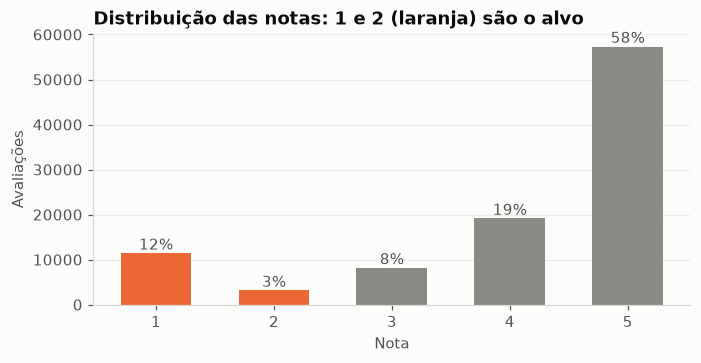

In [7]:
taxa = base["avaliacao_negativa"].mean()
print(f"Taxa de avaliação negativa (nota 1 ou 2): {taxa:.1%}")

con = conectar()
notas = con.sql("SELECT review_score AS nota, COUNT(*) AS n FROM order_reviews GROUP BY 1 ORDER BY 1").df()
con.close()

fig, ax = plt.subplots(figsize=(7, 3.2))
cores = [g.LARANJA if n <= 2 else g.CINZA for n in notas["nota"]]
ax.bar(notas["nota"].astype(str), notas["n"], color=cores, width=0.6)
for x, n in zip(notas["nota"].astype(str), notas["n"]):
    ax.text(x, n, f"{n / notas['n'].sum():.0%}", ha="center", va="bottom", color=g.TEXTO_SECUNDARIO)
ax.set_title("Distribuição das notas: 1 e 2 (laranja) são o alvo")
ax.set_xlabel("Nota")
ax.set_ylabel("Avaliações")
ax.grid(axis="x", visible=False)
g.salvar(fig, "01_distribuicao_notas")
plt.show()

Cerca de 13% dos pedidos recebem nota 1 ou 2. É um problema **desbalanceado**: um modelo que sempre responde "não vai avaliar mal" acertaria 87% das vezes e seria inútil. Por isso a acurácia não serve como métrica (detalhes no notebook 2).

### Entrega: o fator mais forte

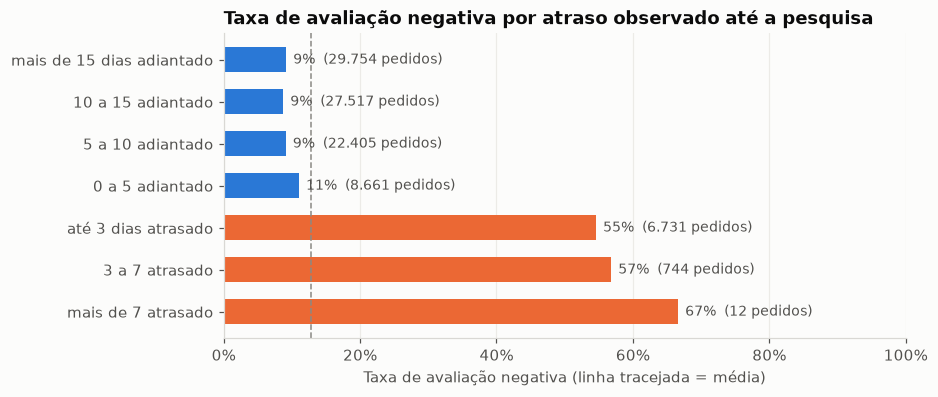

,taxa,pedidos
dias_atraso_observado,,
mais de 15 dias adiantado,0.092,29754
10 a 15 adiantado,0.088,27517
5 a 10 adiantado,0.091,22405
0 a 5 adiantado,0.111,8661
até 3 dias atrasado,0.546,6731
3 a 7 atrasado,0.569,744
mais de 7 atrasado,0.667,12


In [8]:
faixas = pd.cut(
    base["dias_atraso_observado"],
    bins=[-np.inf, -15, -10, -5, 0, 3, 7, np.inf],
    labels=["mais de 15 dias adiantado", "10 a 15 adiantado", "5 a 10 adiantado",
            "0 a 5 adiantado", "até 3 dias atrasado", "3 a 7 atrasado", "mais de 7 atrasado"],
)
por_faixa = base.groupby(faixas, observed=True)["avaliacao_negativa"].agg(taxa="mean", pedidos="size")

fig, ax = plt.subplots(figsize=(8, 3.6))
cores = [g.AZUL if i < 4 else g.LARANJA for i in range(len(por_faixa))]
ax.barh(por_faixa.index.astype(str), por_faixa["taxa"], color=cores, height=0.6)
for y, (t, n) in enumerate(zip(por_faixa["taxa"], por_faixa["pedidos"])):
    ax.text(t + 0.01, y, f"{t:.0%}  ({n:,} pedidos)".replace(",", "."), va="center", color=g.TEXTO_SECUNDARIO, fontsize=9)
ax.axvline(taxa, color=g.CINZA, linestyle="--", linewidth=1)
ax.set_xlim(0, 1)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Taxa de avaliação negativa por atraso observado até a pesquisa")
ax.set_xlabel("Taxa de avaliação negativa (linha tracejada = média)")
ax.grid(axis="y", visible=False)
g.salvar(fig, "02_atraso_vs_negativa")
plt.show()
por_faixa

In [9]:
base.groupby("entregue_antes_pesquisa")["avaliacao_negativa"].agg(taxa="mean", pedidos="size")

,taxa,pedidos
entregue_antes_pesquisa,,
0,0.493,8281
1,0.093,87543


O padrão é claro: **quando o prazo estoura, a taxa de avaliação negativa explode**. Pedidos que ainda não tinham chegado quando a pesquisa foi enviada têm cerca de 49% de notas ruins, contra 9% dos entregues. (A faixa "mais de 7 dias atrasado" tem só 12 pedidos, porque a pesquisa costuma sair logo após o prazo; não vale tirar conclusão dela isoladamente.)

Repare também que a relação não é linear: entre "muito adiantado" e "pouco adiantado" quase não há diferença, e a taxa só dispara quando o prazo é ultrapassado. Modelos baseados em árvore capturam esse tipo de degrau naturalmente; uma regressão logística precisaria de transformações manuais.

### Pedidos com vários itens ou vendedores

In [10]:
resumo = []
for col, nome in [("n_itens", "itens"), ("n_vendedores", "vendedores")]:
    grupo = base.groupby(base[col].clip(upper=3))["avaliacao_negativa"].agg(taxa="mean", pedidos="size")
    grupo.index = [f"{int(i)}{'+' if i == 3 else ''} {nome if i > 1 else nome[:-1]}" for i in grupo.index]
    resumo.append(grupo)
resumo = pd.concat(resumo)
resumo

,taxa,pedidos
1 iten,0.112,86296
2 itens,0.254,7319
3+ itens,0.313,2209
1 vendedore,0.123,94563
2 vendedores,0.468,1202
3+ vendedores,0.644,59


In [11]:
# Mesmo entre pedidos entregues antes da pesquisa, o efeito continua.
entregues = base[base["entregue_antes_pesquisa"] == 1]
entregues.groupby(entregues["n_itens"] > 1)["avaliacao_negativa"].agg(taxa="mean", pedidos="size").rename(
    index={False: "1 item", True: "2 ou mais itens"}
)

,taxa,pedidos
n_itens,,
1 item,0.076,78607
2 ou mais itens,0.247,8936


Pedidos com **dois ou mais vendedores têm cerca de 47% de avaliações negativas**, quase quatro vezes a média. E mesmo entre pedidos já entregues, ter mais de um item triplica a taxa (de cerca de 8% para 25%).

**Hipótese:** entrega parcial. Itens de vendedores diferentes saem em pacotes separados; o primeiro chega, o sistema registra o pedido como entregue, a pesquisa é enviada, e o cliente avalia mal porque ainda falta parte da compra. Os dados não têm a data de entrega por item para confirmar, mas é uma hipótese forte e acionável: o time poderia avisar o cliente quando um pedido vem em mais de um pacote.

### Histórico do vendedor

In [12]:
quintil = pd.qcut(base["vendedor_taxa_negativa_previa"], 5,
                  labels=["20% melhores", "2º quintil", "3º quintil", "4º quintil", "20% piores"])
base.groupby(quintil, observed=True)["avaliacao_negativa"].agg(taxa="mean", pedidos="size")

,taxa,pedidos
vendedor_taxa_negativa_previa,,
20% melhores,0.094,19053
2º quintil,0.110,19050
3º quintil,0.115,19051
4º quintil,0.135,19051
20% piores,0.186,19052


O histórico ajuda: pedidos de vendedores no quintil com pior histórico têm cerca do dobro da taxa negativa dos melhores. Como a variável só usa o passado, essa relação é legítima.

### Evolução no tempo

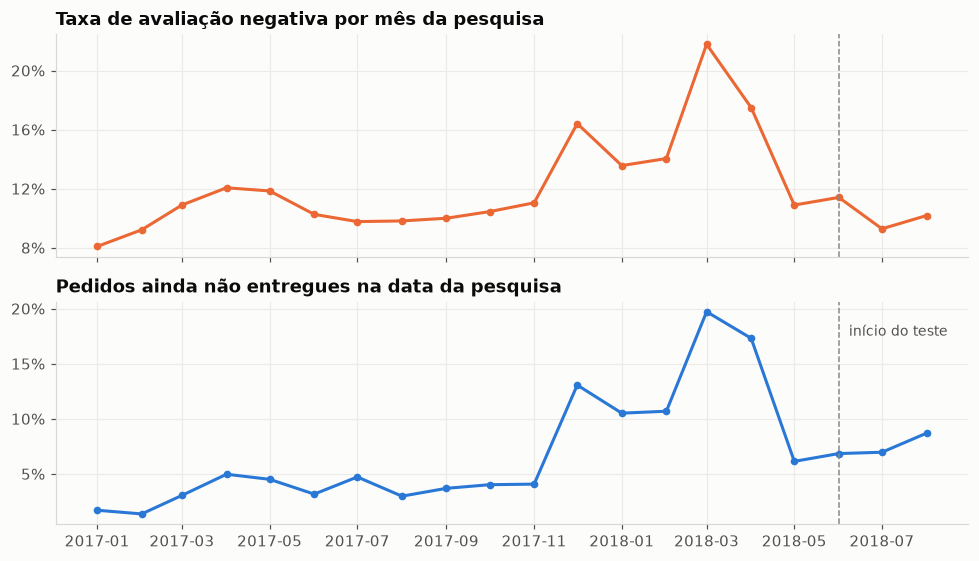

In [13]:
mensal = (
    base.set_index("data_pesquisa")
    .loc["2017-01-01":]
    .resample("MS")
    .agg(taxa_negativa=("avaliacao_negativa", "mean"),
         nao_entregue=("entregue_antes_pesquisa", lambda s: 1 - s.mean()),
         pedidos=("avaliacao_negativa", "size"))
)

fig, axes = plt.subplots(2, 1, figsize=(9, 5.2), sharex=True)
axes[0].plot(mensal.index, mensal["taxa_negativa"], color=g.LARANJA, marker="o", markersize=4)
axes[0].set_title("Taxa de avaliação negativa por mês da pesquisa")
axes[1].plot(mensal.index, mensal["nao_entregue"], color=g.AZUL, marker="o", markersize=4)
axes[0].yaxis.set_major_locator(plt.MultipleLocator(0.04))
axes[1].yaxis.set_major_locator(plt.MultipleLocator(0.05))
axes[1].set_title("Pedidos ainda não entregues na data da pesquisa")
for ax in axes:
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.axvline(pd.Timestamp("2018-06-01"), color=g.CINZA, linestyle="--", linewidth=1)
axes[1].text(pd.Timestamp("2018-06-08"), axes[1].get_ylim()[1] * 0.85, "início do teste",
             color=g.TEXTO_SECUNDARIO, fontsize=9)
fig.tight_layout()
g.salvar(fig, "03_evolucao_mensal")
plt.show()

Os dois gráficos sobem e descem juntos: os picos de avaliação negativa (dezembro de 2017 e março de 2018) coincidem com os picos de pedidos não entregues no prazo. Isso reforça que **logística é o principal motor das notas ruins**.

Também mostra algo importante para a modelagem: o comportamento muda ao longo do tempo. O período de teste (a partir de junho de 2018, linha tracejada) teve menos atrasos que o período de treino. Esperamos que as métricas no teste fiquem diferentes das da validação, e o notebook 2 discute isso.

### Categoria, frete e distância

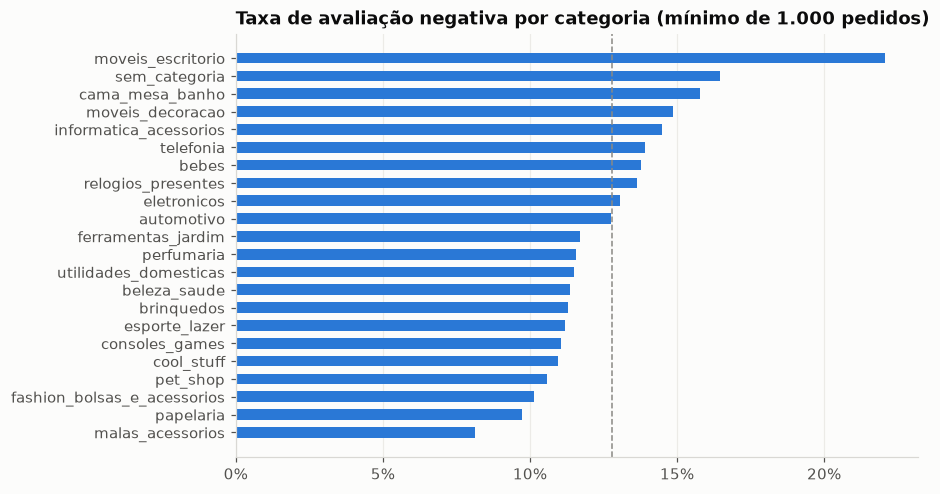

In [14]:
por_categoria = (
    base.groupby("categoria")["avaliacao_negativa"].agg(taxa="mean", pedidos="size")
    .query("pedidos >= 1000")
    .sort_values("taxa")
)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(por_categoria.index, por_categoria["taxa"], color=g.AZUL, height=0.6)
ax.axvline(taxa, color=g.CINZA, linestyle="--", linewidth=1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Taxa de avaliação negativa por categoria (mínimo de 1.000 pedidos)")
ax.grid(axis="y", visible=False)
g.salvar(fig, "04_categorias")
plt.show()

In [15]:
for col in ["distancia_km", "razao_frete_produtos", "prazo_prometido_dias"]:
    tabela = base.groupby(pd.qcut(base[col], 5), observed=True)["avaliacao_negativa"].mean()
    print(f"\n{col}")
    print(tabela.round(3).to_string())


distancia_km
distancia_km
(-0.001, 116.168]     0.104
(116.168, 347.906]    0.123
(347.906, 529.647]    0.128
(529.647, 876.259]    0.136
(876.259, 3399.191]   0.150

razao_frete_produtos
razao_frete_produtos
(-0.001, 0.115]   0.124
(0.115, 0.183]    0.123
(0.183, 0.274]    0.124
(0.274, 0.435]    0.135
(0.435, 21.447]   0.135

prazo_prometido_dias
prazo_prometido_dias
(2.041, 16.75]      0.099
(16.75, 21.417]     0.129
(21.417, 25.167]    0.132
(25.167, 30.167]    0.136
(30.167, 155.167]   0.143


Categoria, distância e frete têm efeito bem menor que a logística. Móveis de escritório se destaca (cerca de 22%), seguido de produtos sem categoria cadastrada, cama, mesa e banho e móveis de decoração: produtos grandes, que dependem de montagem ou de expectativa visual. Malas, papelaria e moda ficam abaixo da média. Distâncias maiores e prazos prometidos mais longos aumentam um pouco o risco, provavelmente porque aumentam a chance de atraso. A razão entre frete e valor dos produtos quase não muda a taxa.

## 1.6 Resumo da análise exploratória

1. **O momento da previsão importa mais que qualquer modelo.** Usar o atraso final da entrega seria vazamento de dados para os clientes que avaliam antes de receber.
2. **Atraso é o fator dominante.** Pedidos não entregues na data da pesquisa têm cerca de 49% de notas ruins.
3. **Pedidos com vários vendedores ou itens são de alto risco**, provavelmente por entrega parcial.
4. **O histórico do vendedor ajuda**, desde que calculado só com o passado.
5. **O comportamento muda no tempo**, então a validação precisa respeitar a ordem cronológica.

Próximo passo: notebook `02_modelagem.ipynb`.